In [1]:
%pip install qiskit matplotlib pylatexenc
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Iterable, Mapping

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector, plot_histogram

ANALYSES = {"statevector", "probabilities", "counts", "bloch"}


# ---------- helpers ----------
def load_circuit(source: QuantumCircuit | str | Path) -> QuantumCircuit:
    """Accept a QuantumCircuit, QASM string, or path to a QASM file."""
    if isinstance(source, QuantumCircuit):
        return source
    text = str(source)
    if isinstance(source, Path) or Path(text).suffix == ".qasm":
        text = Path(text).read_text()
    if "OPENQASM 3" in text:
        from qiskit import qasm3
        return qasm3.loads(text)
    return QuantumCircuit.from_qasm_str(text)


def circuit_stats(qc: QuantumCircuit) -> dict[str, Any]:
    ops = dict(qc.count_ops())
    two_q = sum(1 for inst in qc.data
                if inst.operation.num_qubits == 2
                and inst.operation.name not in ("barrier",))
    return {
        "qubits": qc.num_qubits,
        "clbits": qc.num_clbits,
        "depth": qc.depth(),
        "size": qc.size(),
        "two_qubit_gates": two_q,
        "gate_counts": ops,
        "free_parameters": sorted(p.name for p in qc.parameters),
    }


def _stats_html(title: str, s: dict) -> str:
    rows = "".join(
        f"<tr><td><b>{k}</b></td><td>{v}</td></tr>" for k, v in s.items()
    )
    return f"<h4>{title}</h4><table>{rows}</table>"


# ---------- output model ----------
@dataclass
class CircuitReport:
    circuit: QuantumCircuit
    figure: Any = None
    stats: dict = field(default_factory=dict)
    transpiled: QuantumCircuit | None = None
    transpiled_figure: Any = None
    transpiled_stats: dict | None = None
    statevector: Statevector | None = None
    probabilities: dict[str, float] | None = None
    counts: dict[str, int] | None = None
    figures: dict[str, Any] = field(default_factory=dict)  # histogram, bloch
    notes: list[str] = field(default_factory=list)

    def _ipython_display_(self):
        from IPython.display import HTML, display
        display(self.figure)
        display(HTML(_stats_html("Circuit stats", self.stats)))
        if self.transpiled is not None:
            display(self.transpiled_figure)
            display(HTML(_stats_html("Transpiled stats", self.transpiled_stats)))
        for fig in self.figures.values():
            display(fig)
        for n in self.notes:
            display(HTML(f"<i>Note: {n}</i>"))
        plt.close("all")


# ---------- main entry point ----------
def show_circuit(
    circuit: QuantumCircuit | str | Path,
    *,
    output: str = "mpl",
    fold: int = 25,
    scale: float = 0.8,
    style: str | dict | None = None,
    reverse_bits: bool = False,
    idle_wires: bool = True,
    bind: Mapping[str, float] | None = None,
    transpile_to: Mapping[str, Any] | None = None,
    analyze: Iterable[str] = (),
    shots: int = 1024,
    seed: int | None = 42,
) -> CircuitReport:
    analyze = set(analyze)
    unknown = analyze - ANALYSES
    if unknown:
        raise ValueError(f"Unknown analyses {unknown}; choose from {ANALYSES}")

    qc = load_circuit(circuit)
    if bind:
        by_name = {p.name: p for p in qc.parameters}
        qc = qc.assign_parameters({by_name[k]: v for k, v in bind.items()})

    draw_kw = dict(output=output, fold=fold, reverse_bits=reverse_bits,
                   idle_wires=idle_wires)
    if output == "mpl":
        draw_kw.update(scale=scale, style=style)

    report = CircuitReport(circuit=qc, stats=circuit_stats(qc))
    report.figure = qc.draw(**draw_kw)

    if transpile_to is not None:
        tqc = transpile(qc, seed_transpiler=seed, **transpile_to)
        report.transpiled = tqc
        report.transpiled_figure = tqc.draw(**draw_kw)
        report.transpiled_stats = circuit_stats(tqc)

    if analyze:
        _run_analyses(qc, report, analyze, shots, seed)
    return report


def _run_analyses(qc, report, analyze, shots, seed):
    if qc.parameters:
        report.notes.append("Analyses skipped: unbound parameters. Use bind={...}.")
        return
    # Statevector simulation needs a unitary circuit: drop final measurements.
    unitary = qc.remove_final_measurements(inplace=False)
    try:
        sv = Statevector(unitary)
    except Exception as e:  # mid-circuit measurement, resets, etc.
        report.notes.append(f"Statevector analysis unavailable: {e}")
        return

    if "statevector" in analyze:
        report.statevector = sv
    if "probabilities" in analyze or "counts" in analyze:
        report.probabilities = sv.probabilities_dict()
    if "probabilities" in analyze:
        report.figures["probabilities"] = plot_histogram(
            report.probabilities, title="Exact probabilities")
    if "counts" in analyze:
        sv.seed(seed)
        report.counts = sv.sample_counts(shots)
        report.figures["counts"] = plot_histogram(
            report.counts, title=f"Sampled counts ({shots} shots)")
    if "bloch" in analyze:
        if qc.num_qubits > 6:
            report.notes.append("Bloch spheres skipped (>6 qubits).")
        else:
            report.figures["bloch"] = plot_bloch_multivector(sv)

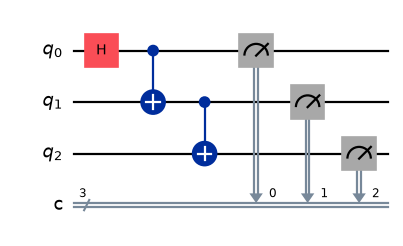

qubits,3
clbits,3
depth,4
size,6
two_qubit_gates,2
gate_counts,"{'measure': 3, 'cx': 2, 'h': 1}"
free_parameters,[]


In [3]:
qc = QuantumCircuit(3, 3)
qc.h(0); qc.cx(0, 1); qc.cx(1, 2)
qc.measure([0, 1, 2], [0, 1, 2])

show_circuit(qc)

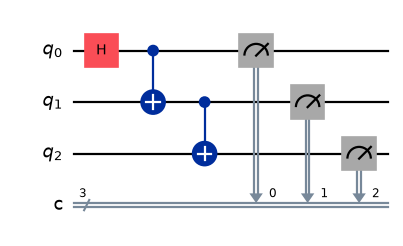

qubits,3
clbits,3
depth,4
size,6
two_qubit_gates,2
gate_counts,"{'measure': 3, 'cx': 2, 'h': 1}"
free_parameters,[]


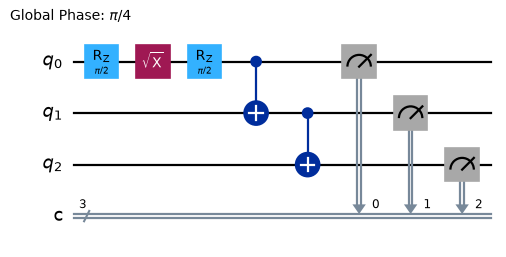

qubits,3
clbits,3
depth,6
size,8
two_qubit_gates,2
gate_counts,"{'measure': 3, 'rz': 2, 'cx': 2, 'sx': 1}"
free_parameters,[]


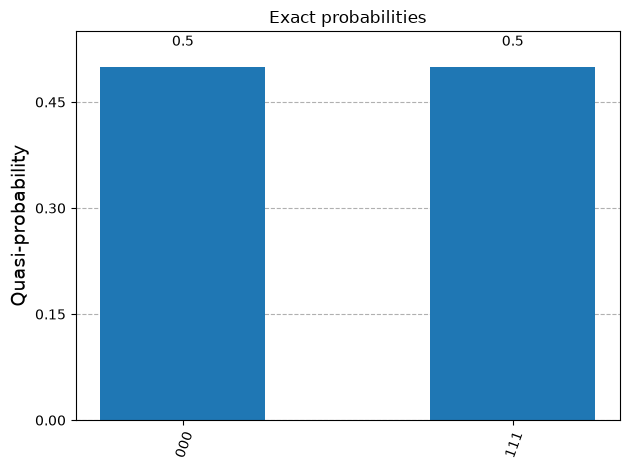

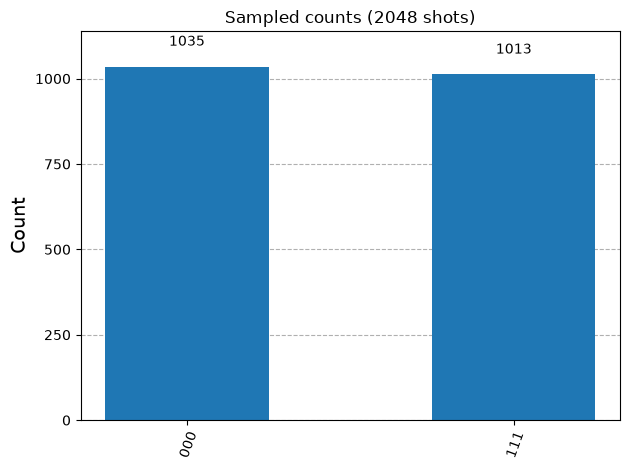

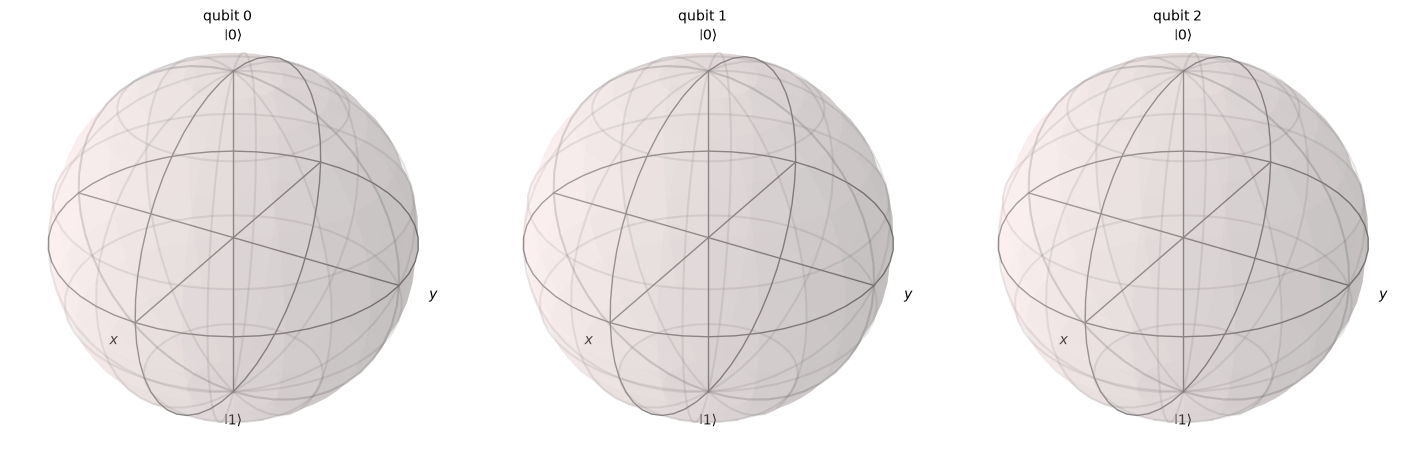

In [4]:
report = show_circuit(
    qc,
    analyze={"probabilities", "counts", "bloch"},
    transpile_to={"basis_gates": ["cx", "rz", "sx", "x"], "optimization_level": 1},
    shots=2048,
)
report

In [5]:
print(report.stats["depth"], report.stats["two_qubit_gates"])
report.probabilities

4 2


{np.str_('000'): np.float64(0.4999999999999999),
 np.str_('111'): np.float64(0.4999999999999999)}

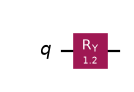

qubits,1
clbits,0
depth,1
size,1
two_qubit_gates,0
gate_counts,{'ry': 1}
free_parameters,[]


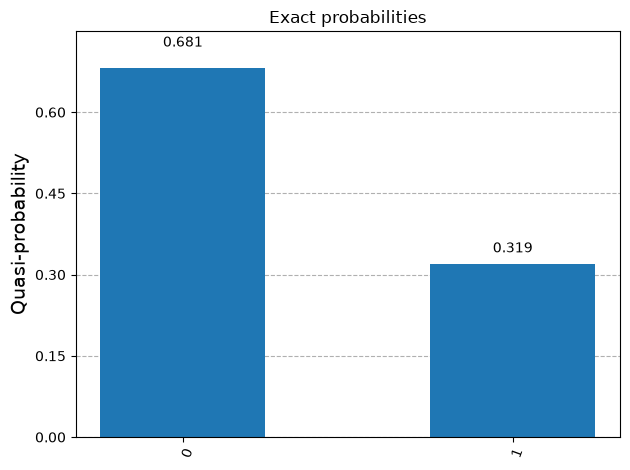

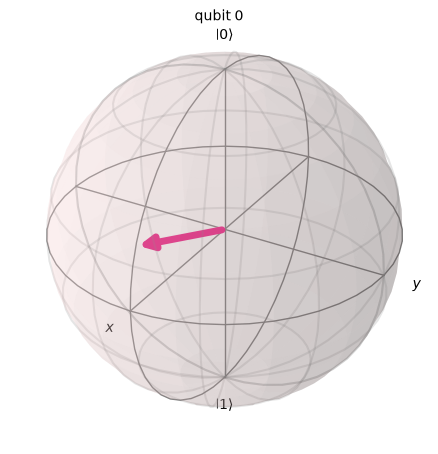

In [6]:
from qiskit.circuit import Parameter

theta = Parameter("theta")
pqc = QuantumCircuit(1)
pqc.ry(theta, 0)

show_circuit(pqc, bind={"theta": 1.2}, analyze={"probabilities", "bloch"})

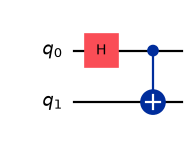

qubits,2
clbits,0
depth,2
size,2
two_qubit_gates,1
gate_counts,"{'h': 1, 'cx': 1}"
free_parameters,[]


In [8]:
qasm = '''OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];
h q[0];
cx q[0],q[1];
'''
show_circuit(qasm, output="mpl")